# Biermann et al. 2022 — Melanoma brain/peripheral metastasis
## 04 · EMT-transcription-factor expression (unconditional final step)

The EMT-TF readout runs regardless of gate outcomes; numbered **04** here because the analysis is
non-branching (Gate 3 NA), so the branching-only correlation/modules notebooks are not produced (§6).
A wide EMT-TF panel (Snail/Zeb/Twist + FOXC/PRRX mesenchymal families; VIM excluded — a mesenchymal
marker, not a TF) is scored, gated on detectable expression, and each factor classified by the
pseudotime end it loads onto. The two most informative factors (origin/body vs terminus) are overlaid
as thresholded expressers on the manifold.

In [2]:
import os, sys, glob, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
import logging
logging.getLogger('harmonypy').setLevel(logging.ERROR)
logging.getLogger('harmonypy').propagate=False
logging.getLogger('harmonypy').disabled=True

In [3]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [4]:
# load signatures (has pseudotime + house layout)
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 91356 | pseudotime 0.0 -> 12.53


In [5]:
# score a WIDE EMT-TF panel; gate on detectable expression; classify each by pseudotime end.
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows=[]
for j,g in enumerate(present):
    x = X[:,j]; expr = x>0; rho,_ = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(origin)', 'LATE(terminus)')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
body_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
terminus_tf = ok.sort_values('rho_vs_t').iloc[-1]['TF']
n_early = int((ok.end=='EARLY(origin)').sum())
print(f'\nexpressed EMT-TFs (frac>3%): {len(ok)}; classified EARLY(origin): {n_early}')
print(f'origin/body factor (min rho) = {body_tf}; terminus factor (max rho) = {terminus_tf}')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 SNAI2      0.142       0.090      0.071    -0.058  EARLY(origin)
 FOXC1      0.027       0.015      0.008    -0.027  EARLY(origin)
 SNAI1      0.008       0.004      0.002    -0.021  EARLY(origin)
 FOXC2      0.001       0.000      0.000     0.007 LATE(terminus)
 PRRX2      0.011       0.006      0.009     0.017 LATE(terminus)
TWIST1      0.132       0.087      0.086     0.019  EARLY(origin)
TWIST2      0.087       0.052      0.079     0.068 LATE(terminus)
 PRRX1      0.233       0.209      0.277     0.073 LATE(terminus)
  ZEB1      0.254       0.152      0.216     0.087 LATE(terminus)
  ZEB2      0.792       0.870      1.170     0.179 LATE(terminus)

expressed EMT-TFs (frac>3%): 6; classified EARLY(origin): 2
origin/body factor (min rho) = SNAI2; terminus factor (max rho) = ZEB2


overlay thresholds (upper quartile among expressers): {'SNAI2': 0.71, 'ZEB2': 1.72} | cells shown: {'SNAI2': 3248, 'ZEB2': 18088}
SNAI2: 14.2% expressing; 3248 shown; mean pseudotime of shown = 0.46
ZEB2: 79.2% expressing; 18088 shown; mean pseudotime of shown = 0.56
saved expression.pdf


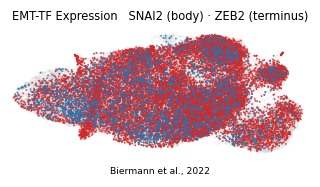

In [6]:
# categorical overlay: thresholded expressers of the two chosen TFs on a grey manifold (reference style)
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr={}
for g in [body_tf, terminus_tf]:
    v = vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos,0.75)) if pos.size else 0.0
sel = {g: vec(g) > thr[g] for g in [body_tf, terminus_tf]}
print('overlay thresholds (upper quartile among expressers):', {g:round(thr[g],2) for g in thr},
      '| cells shown:', {g:int(sel[g].sum()) for g in sel})
order = sorted([body_tf, terminus_tf], key=lambda g: -int(sel[g].sum()))
colors = {body_tf:'tab:blue', terminus_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=6, alpha=.25, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=6, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {body_tf} (body) \u00b7 {terminus_tf} (terminus)', size=7.5)
ax.text(.5,-.14,'Biermann et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [body_tf, terminus_tf]:
    mk = sel[g]
    print(f'{g}: {(vec(g)>0).mean()*100:.1f}% expressing; {int(mk.sum())} shown; mean pseudotime of shown = {tn[mk].mean():.2f}')
print('saved expression.pdf')